TITANIC DATASET - DATA ANALYSIS

Dataset loaded successfully!
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123     

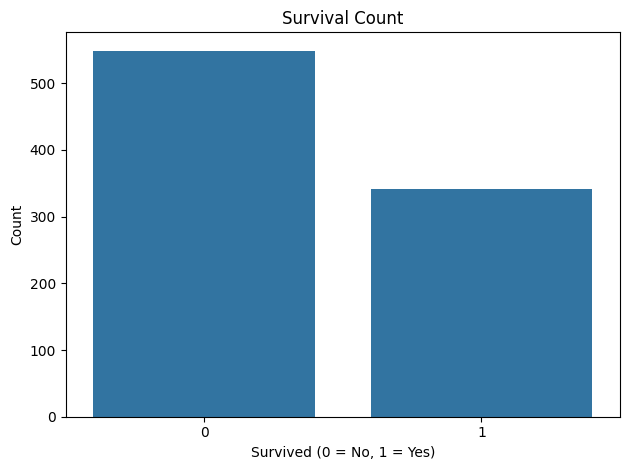

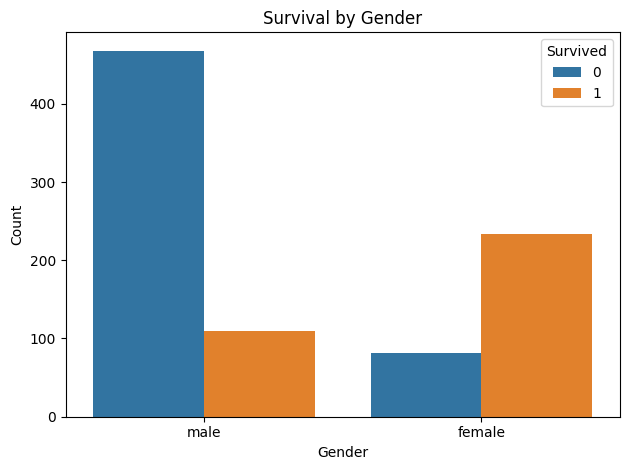

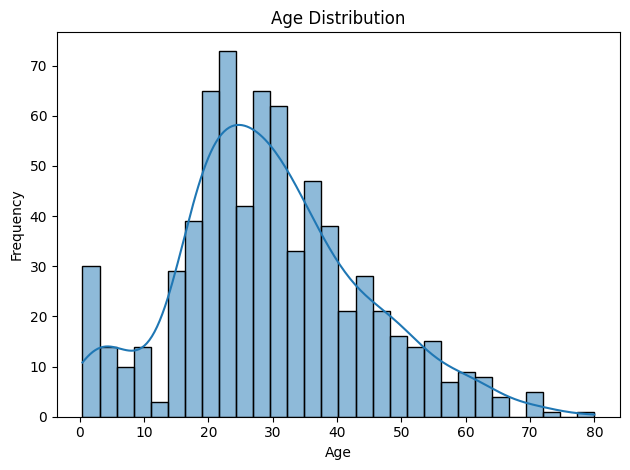

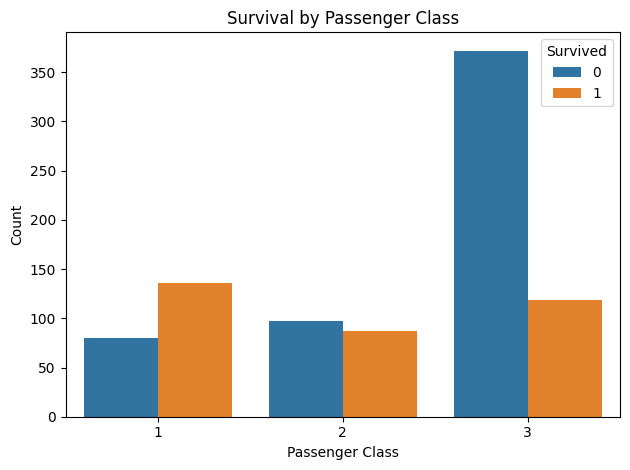

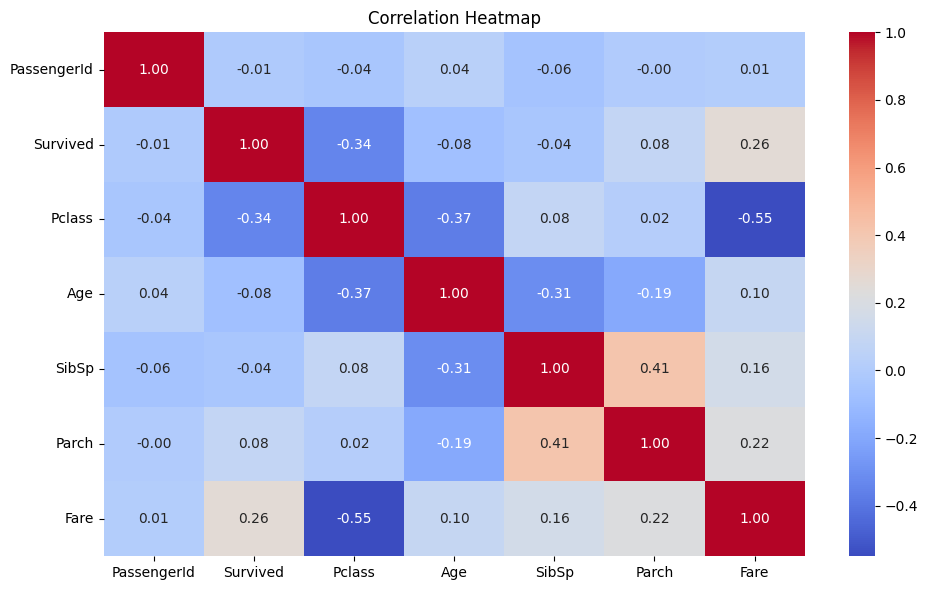


Missing Values After Handling:
Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

Encoded Dataset:
   Survived  Pclass   Age  SibSp  Parch     Fare  Sex_male  Embarked_Q  \
0         0       3  22.0      1      0   7.2500         1           0   
1         1       1  38.0      1      0  71.2833         0           0   
2         1       3  26.0      0      0   7.9250         0           0   
3         1       1  35.0      1      0  53.1000         0           0   
4         0       3  35.0      0      0   8.0500         1           0   

   Embarked_S  
0           1  
1           0  
2           1  
3           1  
4           1  

Encoded Column Names:
['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S']

Feature Shape: (891, 8)
Target Shape: (891,)

Features:
   Pclass   Age  SibSp  Parch     Fare  Sex_male  Embarked_Q  Embarked_S
0       3  22.0      1      0   7.2

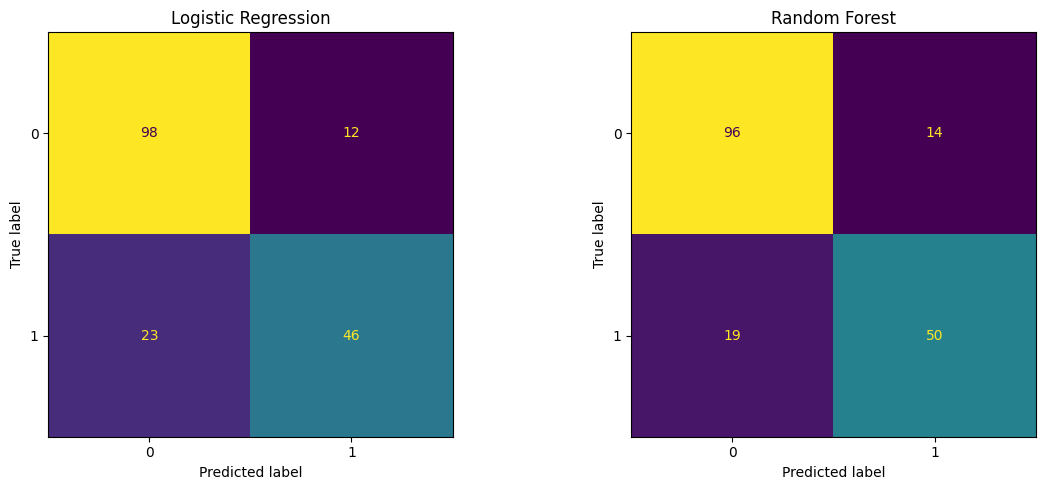


MODEL PERFORMANCE COMPARISON
              Model  Accuracy  Precision  Recall  F1-Score
Logistic Regression    0.8045     0.7931  0.6667    0.7244
      Random Forest    0.8156     0.7812  0.7246    0.7519

Results saved to model_comparison_results.csv

MODEL COMPARISON CONCLUSION
Better model based on F1-score: Random Forest
F1-Score: 0.7519

The selected model achieved the highest F1-score among the two tested models.
Review accuracy, precision, recall and confusion matrices before making the final decision.

ALL MODEL TRAINING AND EVALUATION STEPS COMPLETED!


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("=" * 60)
print("TITANIC DATASET - DATA ANALYSIS")
print("=" * 60)


# STEP 2: Load Dataset

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

try:
    df = pd.read_csv(url)
    print("\nDataset loaded successfully!")
except Exception as e:
    print("Error loading dataset:", e)
    print("Check your internet connection.")
    raise SystemExit

print(df.head())


# STEP 3: Understand the Dataset

print("\nDataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nFirst 5 Rows:")
print(df.head())


# STEP 4: Exploratory Data Analysis (EDA)

# 4.1 Missing Values

print("\nMissing Values:")
print(df.isnull().sum())

print("\nMissing Value Percentage:")
print((df.isnull().sum() / len(df) * 100).round(2))


# 4.2 Duplicate Rows

print("\nDuplicate Rows:", df.duplicated().sum())


# 4.3 Survival Count

sns.countplot(data=df, x="Survived")
plt.title("Survival Count")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


# 4.4 Survival by Gender

sns.countplot(data=df, x="Sex", hue="Survived")
plt.title("Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


# 4.5 Age Distribution

sns.histplot(data=df, x="Age", bins=30, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# 4.6 Survival by Passenger Class

sns.countplot(data=df, x="Pclass", hue="Survived")
plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


# 4.7 Correlation Heatmap

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 6))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


# STEP 5: Handle Missing Values

df_clean = df.copy()

# Fill numerical missing values using median
df_clean["Age"] = df_clean["Age"].fillna(
    df_clean["Age"].median()
)

df_clean["Fare"] = df_clean["Fare"].fillna(
    df_clean["Fare"].median()
)

# Fill categorical missing values using mode
df_clean["Embarked"] = df_clean["Embarked"].fillna(
    df_clean["Embarked"].mode()[0]
)

# Remove unnecessary columns and Cabin
df_clean.drop(
    columns=["Cabin", "PassengerId", "Name", "Ticket"],
    inplace=True
)

print("\nMissing Values After Handling:")
print(df_clean.isnull().sum())


# STEP 6: Encode Categorical Variables

df_encoded = pd.get_dummies(
    df_clean,
    columns=["Sex", "Embarked"],
    drop_first=True,
    dtype=int
)

print("\nEncoded Dataset:")
print(df_encoded.head())

print("\nEncoded Column Names:")
print(df_encoded.columns.tolist())


# STEP 7: Prepare Features and Target

X = df_encoded.drop("Survived", axis=1)
y = df_encoded["Survived"]

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeatures:")
print(X.head())

print("\nTarget:")
print(y.head())


# STEP 8: Split Dataset into Training and Testing Sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


# STEP 9: Feature Scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nFeature Scaling Completed!")
print("Scaled Training Data Shape:", X_train_scaled.shape)
print("Scaled Testing Data Shape:", X_test_scaled.shape)


# STEP 10: Final Verification

print("\n" + "=" * 60)
print("FINAL DATASET SUMMARY")
print("=" * 60)

print("Total Samples:", len(df_encoded))
print("Total Features:", X.shape[1])
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))


print(
    "Missing Values:",
    df_encoded.isnull().sum().sum()
)

print("Original Duplicate Rows:", df.duplicated().sum())

print("\nAll preprocessing steps completed successfully!")


# STEP 11: Save Processed Dataset

df_encoded.to_csv("titanic_processed.csv", index=False)

print("\nProcessed dataset saved as titanic_processed.csv")

# Save training and testing data separately
X_train.to_csv("X_train.csv", index=False)
X_test.to_csv("X_test.csv", index=False)

y_train.to_csv("y_train.csv", index=False)
y_test.to_csv("y_test.csv", index=False)

print("Training and testing files saved successfully!")

print("\nPROGRAM COMPLETED SUCCESSFULLY!")
# ============================================================
# STEP 12: TRAIN TWO MACHINE LEARNING MODELS
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("\n" + "=" * 60)
print("MACHINE LEARNING MODEL TRAINING")
print("=" * 60)

# Model 1: Logistic Regression

model1 = LogisticRegression(max_iter=1000)

model1.fit(X_train_scaled, y_train)

y_pred1 = model1.predict(X_test_scaled)

print("\nLogistic Regression Training Completed!")


# Model 2: Random Forest Classifier

model2 = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model2.fit(X_train, y_train)

y_pred2 = model2.predict(X_test)

print("Random Forest Training Completed!")


# ============================================================
# STEP 13: EVALUATE BOTH MODELS
# ============================================================

def evaluate_model(name, y_true, y_pred):

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true, y_pred, zero_division=0
    )

    recall = recall_score(
        y_true, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_true, y_pred, zero_division=0
    )

    print("\nModel:", name)
    print("-" * 40)

    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-Score : {f1:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y_true, y_pred, zero_division=0
    ))

    return {
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }


results = []

results.append(
    evaluate_model(
        "Logistic Regression", y_test, y_pred1
    )
)

results.append(
    evaluate_model(
        "Random Forest", y_test, y_pred2
    )
)


# ============================================================
# STEP 14: CONFUSION MATRICES
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred1,
    ax=axes[0],
    colorbar=False
)

axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred2,
    ax=axes[1],
    colorbar=False
)

axes[1].set_title("Random Forest")

plt.tight_layout()
plt.show()


# ============================================================
# STEP 15: COMPARE MODEL PERFORMANCE
# ============================================================

results_df = pd.DataFrame(results)

print("\n" + "=" * 60)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 60)

print(results_df.round(4).to_string(index=False))


# Save evaluation results
results_df.to_csv(
    "model_comparison_results.csv",
    index=False
)

print("\nResults saved to model_comparison_results.csv")


# ============================================================
# STEP 16: IDENTIFY THE BETTER MODEL
# ============================================================

# Compare models using F1-score
best_index = results_df["F1-Score"].idxmax()

best_model_name = results_df.loc[
    best_index, "Model"
]

best_f1 = results_df.loc[
    best_index, "F1-Score"
]

print("\n" + "=" * 60)
print("MODEL COMPARISON CONCLUSION")
print("=" * 60)

print("Better model based on F1-score:", best_model_name)
print(f"F1-Score: {best_f1:.4f}")

print(
    "\nThe selected model achieved the highest F1-score "
    "among the two tested models."
)

print(
    "Review accuracy, precision, recall and confusion "
    "matrices before making the final decision."
)

print("\nALL MODEL TRAINING AND EVALUATION STEPS COMPLETED!")
